# Bài 2 — Softmax Regression bằng NumPy

Phân loại 10 chữ số từ 0 đến 9 trên MNIST.

## 1. Đọc và chuẩn hóa dữ liệu

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if (ROOT / 'Lab2_du_lieu_MNIST').is_dir():
    ROOT = ROOT / 'Lab2_du_lieu_MNIST'

data = np.load(ROOT / 'data' / 'mnist.npz')
X_train = data['X_train']
X_test = data['X_test']
y_train = data['y_train']
y_test = data['y_test']

X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
output = ROOT / 'results' / 'bai2_softmax_numpy'
output.mkdir(parents=True, exist_ok=True)

## 2. One-hot, softmax và loss

In [2]:
n_classes = 10
Y_train = np.eye(n_classes, dtype=np.float32)[y_train]

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def loss_function(Y, P):
    P = np.clip(P, 1e-15, 1)
    return -np.sum(Y * np.log(P)) / len(Y)

## 3. Huấn luyện bằng Gradient Descent

In [3]:
W = np.zeros((X_train.shape[1], n_classes), dtype=np.float32)
b = np.zeros(n_classes, dtype=np.float32)
learning_rate = 0.1
epochs = 500
losses = [float(loss_function(Y_train, softmax(X_train @ W + b)))]

for epoch in range(epochs):
    P = softmax(X_train @ W + b)
    error = P - Y_train
    dW = X_train.T @ error / len(X_train)
    db = np.mean(error, axis=0)
    W = W - learning_rate * dW
    b = b - learning_rate * db

    P = softmax(X_train @ W + b)
    loss = loss_function(Y_train, P)
    losses.append(float(loss))

## 4. Đồ thị loss

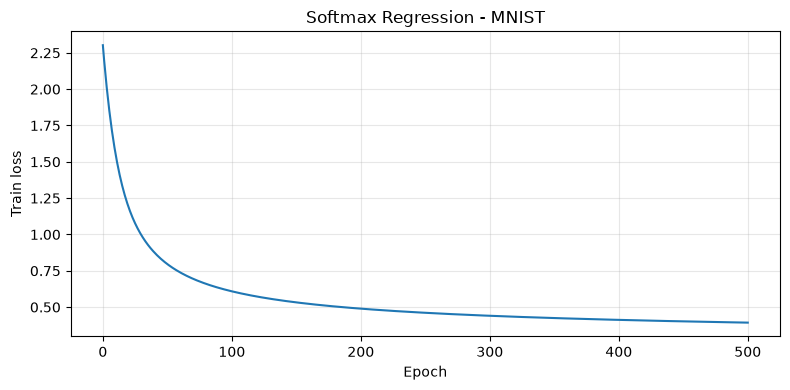

In [4]:
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Train loss')
plt.title('Softmax Regression - MNIST')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output / 'training_loss.png', dpi=160)
plt.show()

## 5. Dự đoán và đánh giá

In [5]:
probabilities = softmax(X_test @ W + b)
y_pred = np.argmax(probabilities, axis=1)

cm = np.zeros((n_classes, n_classes), dtype=int)
for i in range(len(y_test)):
    cm[y_test[i], y_pred[i]] += 1

accuracy = float(np.mean(y_test == y_pred))
rows = []
scores = []
print('Lớp   Precision   Recall      F1      Support')
for c in range(n_classes):
    tp = int(cm[c, c])
    fp = int(cm[:, c].sum()) - tp
    fn = int(cm[c, :].sum()) - tp
    support = int(cm[c, :].sum())
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    print(f'{c:3d}   {precision:9.4f}   {recall:6.4f}   {f1:6.4f}   {support:5d}')
    scores.append([precision, recall, f1])
    rows.append({'label': c, 'precision': precision, 'recall': recall,
                 'f1': f1, 'support': support})

macro = np.mean(scores, axis=0)
print('Accuracy:', round(accuracy, 4))
print('Macro Precision:', round(float(macro[0]), 4))
print('Macro Recall:', round(float(macro[1]), 4))
print('Macro F1:', round(float(macro[2]), 4))
print('Ma trận nhầm lẫn:')
print(cm)

Lớp   Precision   Recall      F1      Support
  0      0.9293   0.9786   0.9533     980
  1      0.9476   0.9718   0.9595    1135
  2      0.9133   0.8576   0.8846    1032
  3      0.8857   0.8901   0.8879    1010
  4      0.8905   0.9196   0.9048     982
  5      0.8843   0.8229   0.8525     892
  6      0.9227   0.9342   0.9284     958
  7      0.9124   0.8911   0.9016    1028
  8      0.8482   0.8604   0.8542     974
  9      0.8669   0.8712   0.8690    1009
Accuracy: 0.9011
Macro Precision: 0.9001
Macro Recall: 0.8997
Macro F1: 0.8996
Ma trận nhầm lẫn:
[[ 959    0    2    3    0    2    7    1    6    0]
 [   0 1103    2    4    1    2    4    0   19    0]
 [  13    7  885   20   15    0   18   22   43    9]
 [   6    1   18  899    1   31    5   15   22   12]
 [   1    6    5    0  903    1   12    1    8   45]
 [  14    6    5   43   15  734   17   10   37   11]
 [  16    3    7    2   13   17  895    1    4    0]
 [   3   20   29    4   11    0    0  916    4   41]
 [   9   10  

## 6. Lưu kết quả

In [6]:
metrics = {'accuracy': accuracy, 'per_class': rows, 'confusion_matrix': cm.tolist(),
           'macro_precision': float(macro[0]), 'macro_recall': float(macro[1]),
           'macro_f1': float(macro[2]), 'learning_rate': learning_rate, 'epochs': epochs,
           'train_samples': len(y_train), 'test_samples': len(y_test),
           'initial_train_loss': losses[0], 'final_train_loss': losses[-1]}
(output / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
np.savetxt(output / 'training_loss.csv', np.column_stack([np.arange(len(losses)), losses]),
           delimiter=',', header='epoch,train_loss', comments='')
np.savetxt(output / 'test_predictions.csv', np.column_stack([y_test, y_pred]),
           delimiter=',', header='true_label,predicted_label', comments='', fmt='%d')
np.savez(output / 'model.npz', W=W, b=b)